# Análisis Exploratorio y Diseño de Investigación: Histórico de Noticias UNISON

Este documento establece las bases teóricas, las hipótesis de investigación periodística y la estrategia de normalización de datos antes de proceder con el desarrollo del pipeline de scraping para el portal de [Noticias Anteriores de la Universidad de Sonora](https://www.unison.mx/noticias-anteriores/).

---

## Fase 1: Mapeo Estructural y Exploración Superficial

### 1. Taxonomía y Navegación
El sitio web de la Universidad de Sonora organiza su archivo histórico de noticias de manera cronológica y temática:
* **Jerarquía Principal:** Las noticias se presentan en un flujo histórico indexado principalmente por **fechas** (mes/año) y paginado.
* **Categorías comunes de una universidad pública:**
  * *Academia y Docencia* (nuevos planes de estudio, acreditaciones).
  * *Investigación y Posgrado* (patentes, publicaciones científicas, proyectos).
  * *Vinculación y Comunidad* (convenios, eventos culturales, deportes, convocatorias).
  * *Administración e Institucional* (procesos de elección de rectoría, presupuestos, comunicados oficiales, huelgas o negociaciones del STEUS/STAUS).

### 2. Inventario de Metadatos por Artículo
Para cada registro de noticia, se identifican potencialmente los siguientes campos del DOM:
* **Título (`Title`):** Cadena de texto principal (usualmente dentro de etiquetas `<h1>` o `<h2>` con clases específicas).
* **Fecha de Publicación (`Date`):** Ubicada comúnmente en un contenedor de metadatos superior o inferior (ej. clase `.post-date`, `.entry-meta` o mediante iconos de calendario).
* **Enlace Permanente (`URL`):** Atributo `href` que dirige a la nota completa.
* **Resumen o Copete (`Excerpt`):** Texto introductorio visible desde la lista de resultados.
* **Categoría o Etiquetas (`Tags`):** Metadatos de clasificación asignados a la nota.
* **Cuerpo de la Noticia (`Body Text`):** (A extraer en la fase de navegación profunda) El contenido completo estructurado en párrafos `<p>`.

### 3. Viabilidad Temporal
El sitio cuenta con una estructura de navegación histórica clara. La presencia de fechas explícitas asociadas a cada publicación garantiza la viabilidad para estructurar un análisis de series de tiempo confiable (ej. volumen de publicaciones por mes, evolución temática anual).

## Fase 2: Formulación de Hipótesis y Ángulos Narrativos

### Hipótesis 1: Evolución del Discurso e Inversión de Prioridades (La Transición Digital y de Enfoque)
* **Planteamiento:** El discurso institucional de la UNISON ha transitado de un enfoque estrictamente administrativo a uno dominado por la "responsabilidad social" y la "digitalización" tras la pandemia.
* **Datos a raspar:** Texto de títulos y resúmenes filtrados por ventanas temporales (ej. 2018-2019 vs. 2021-2023) para realizar análisis de frecuencia de palabras clave y modelado de temas (Topic Modeling).

### Hipótesis 2: Redes de Protagonismo y Brecha de Visibilidad Interfacultades
* **Planteamiento:** Existe una asimetría crítica en la visibilidad mediática de las distintas divisiones académicas. Las ciencias exactas y de la salud acaparan la cobertura informativa, mientras que las ciencias sociales o artes quedan marginadas en la narrativa oficial.
* **Datos a raspar:** Menciones de palabras clave asociadas a departamentos, facultades o campus específicos (ej. "Hermosillo", "Navojoa", "Caborca") dentro del cuerpo de las noticias para mapear la descentralización de la información.

### Hipótesis 3: Gestión de Crisis y Respuestas Discursivas (El Fenómeno de las Huelgas)
* **Planteamiento:** Durante periodos de conflicto laboral (negociaciones y huelgas de sindicatos como STAUS/STEUS), el flujo informativo institucional sufre alteraciones drásticas: o bien incrementa con comunicados defensivos unidireccionales, o se genera un vacío informativo respecto al conflicto.
* **Datos a raspar:** Volumen diario de noticias publicadas durante los meses de abril y mayo de cada año analizado, evaluando el análisis de sentimiento del texto en esos rangos temporales específicos.

## Fase 3: Estrategia de Limpieza y Normalización del DOM

Para asegurar la integridad de la base de datos final, se implementarán las siguientes reglas de procesamiento de datos:

### 1. Limpieza de Texto (HTML-to-Text)
* **Eliminación de Ruido:** Remover de forma proactiva elementos `<script>`, `<style>`, selectores de redes sociales, barras de navegación y pies de página antes de extraer el texto plano.
* **Decodificación de Entidades:** Utilizar parser estándar (como `lxml` en BeautifulSoup) para resolver entidades HTML comunes (ej. `&nbsp;`, `&aacute;`, `&quot;`).
* **Sanitización de Caracteres:** Reemplazar saltos de línea repetidos (`\n`, `\r`), tabulaciones (`\t`) y espacios en blanco múltiples por un único espacio en blanco regular.

### 2. Normalización Temporal
* **Formato Origen:** El sitio suele presentar fechas en lenguaje natural español (ej. *"24 de Octubre de 2023"*).
* **Normalización:** Diseñar un diccionario de traducción de meses (`"enero" -> "01"`, `"octubre" -> "10"`, etc.), extraer el patrón numérico mediante expresiones regulares (`re`) y convertir a formato estándar **ISO 8601** (`YYYY-MM-DD`) usando `datetime` de Python.

### 3. Manejo de Valores Nulos (Data Quality)
* **Autor/Dependencia Faltante:** Asignar por defecto el valor categórico `"Institucional / No especificado"`.
* **Cuerpo de Texto Vacío:** Si una noticia consiste únicamente en una imagen o galería sin texto, marcar la fila con un flag de calidad `has_body = False` para decidir su exclusión o inclusión en análisis cuantitativos de volumen.
* **Fecha Faltante:** Si una noticia carece de fecha discernible, se descartará del pipeline de series temporales o se le asignará la fecha estimada del artículo adyacente (documentando formalmente esta regla de imputación).

In [ ]:
import requests
from bs4 import BeautifulSoup

# URL objetivo para la fase exploratoria
url_objetivo = 'https://www.unison.mx/noticias-anteriores/'

# Definimos un User-Agent para simular un navegador estándar y evitar bloqueos preventivos
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'
}

try:
    print(f"Iniciando petición de prueba a: {url_objetivo}")
    response = requests.get(url_objetivo, headers=headers, timeout=15)

    # Validamos el estado de la respuesta
    if response.status_code == 200:
        print("¡Conexión exitosa! Estado de respuesta: 200")
        soup = BeautifulSoup(response.text, 'html.parser')

        # Imprimimos el título de la página para validar que el parseo inicial es correcto
        page_title = soup.title.string.strip() if soup.title else "Sin etiqueta de título"
        print(f"Título del sitio web recuperado: {page_title}")
        print("La estructura del HTML está lista para ser analizada en busca de contenedores de noticias.")
    else:
        print(f"Advertencia: El sitio respondió con código de estado {response.status_code}")

except Exception as e:
    print(f"Ocurrió un error al intentar conectar con el servidor: {e}")

Iniciando petición de prueba a: https://www.unison.mx/noticias-anteriores/
¡Conexión exitosa! Estado de respuesta: 200
Título del sitio web recuperado: Noticias Anteriores – Universidad de Sonora
La estructura del HTML está lista para ser analizada en busca de contenedores de noticias.


## Desarrollo de la Fase 1: Mapeo Estructural y Análisis del DOM

En esta sección ejecutaremos código para inspeccionar el árbol HTML (DOM) del portal de noticias anteriores de la UNISON. Buscaremos de forma sistemática los contenedores de las notas, sus títulos, enlaces permanentes, fechas de publicación y extractos.

In [ ]:
import requests
from bs4 import BeautifulSoup
import re

# Volvemos a solicitar el HTML inicial de la página de filtros
response = requests.get(url_objetivo, headers=headers, timeout=15)
soup = BeautifulSoup(response.text, 'html.parser')

# 1. Inspección y extracción automática de los parámetros de filtrado histórico (Años y Meses)
# Buscamos los selectores <select> en el formulario de la página
select_anio = soup.find('select', {'name': lambda x: x and ('anio' in x or 'year' in x or 'ano' in x)}) or soup.find(id=lambda x: x and ('anio' in x or 'year' in x))
select_mes = soup.find('select', {'name': lambda x: x and ('mes' in x or 'month' in x)}) or soup.find(id=lambda x: x and ('mes' in x or 'month' in x))

# Si no los encuentra por nombre, los extraemos analizando todos los selects de la página
if not select_anio or not select_mes:
    all_selects = soup.find_all('select')
    if len(all_selects) >= 2:
        select_anio = all_selects[0]
        select_mes = all_selects[1]

# Extraemos los valores de los años
anios_disponibles = []
if select_anio:
    anios_disponibles = [opt.get('value') for opt in select_anio.find_all('option') if opt.get('value') and opt.get('value').isdigit()]

# Extraemos los valores de los meses
meses_disponibles = []
if select_mes:
    meses_disponibles = [opt.get('value') for opt in select_mes.find_all('option') if opt.get('value') and opt.get('value') != ""]

# En caso de no poder parsear los selects dinámicamente, definimos el fallback histórico con base en la interfaz de usuario
if not anios_disponibles:
    anios_disponibles = [str(a) for a in range(2003, 2027)]
if not meses_disponibles:
    meses_disponibles = [str(m) for m in range(1, 13)]

print(f"Rango de años detectado para el raspado: {min(anios_disponibles)} a {max(anios_disponibles)} ({len(anios_disponibles)} años)")
print(f"Meses detectados para el raspado: {meses_disponibles}")

Rango de años detectado para el raspado: 2003 a 2026 (24 años)
Meses detectados para el raspado: ['-', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12']


In [ ]:
import time
import re
import requests
from bs4 import BeautifulSoup
import pandas as pd

# Diccionario de meses en español para conversión a ISO 8601
MESES_DICT = {
    'enero': '01', 'febrero': '02', 'marzo': '03', 'abril': '04',
    'mayo': '05', 'junio': '06', 'julio': '07', 'agosto': '08',
    'septiembre': '09', 'octubre': '10', 'noviembre': '11', 'diciembre': '12'
}

def normalizar_fecha_iso(texto_fecha):
    if not isinstance(texto_fecha, str):
        return None
    texto = texto_fecha.lower().strip()
    match = re.search(r'(\d{1,2})\s+de\s+([a-záéíóúñ]+)\s+de\s+(\d{4})', texto)
    if match:
        dia = match.group(1).zfill(2)
        mes_txt = match.group(2)
        anio = match.group(3)
        mes_txt_limpio = re.sub(r'[áéíóú]', lambda m: {'á':'a','é':'e','í':'i','ó':'o','ú':'u'}[m.group(0)], mes_txt)
        mes_num = MESES_DICT.get(mes_txt_limpio, '01')
        return f"{anio}-{mes_num}-{dia}"
    return texto_fecha

def limpiar_titulo_texto(t):
    if not isinstance(t, str):
        return ""
    t = re.sub(r'\s+', ' ', t)
    t = t.strip().rstrip(',')
    return t

noticias_historicas = []
patron_fecha = r'^\d{1,2}\s+de\s+[a-zA-ZáéíóúÁÉÍÓÚ]+\s+de\s+\d{4}$'

def extraer_noticias_por_periodo(anio, mes):
    url_consulta = "https://www.unison.mx/noticias-anteriores/"
    # Payload exacto coincidiendo con las variables del formulario inspeccionado
    payload = {
        'anio': str(anio),
        'mes': str(mes),
        'pclave': '',
        'opc': 'historialnoti', # Campo oculto indispensable
        'submit': 'BUSCAR'     # Nombre del botón de envío
    }
    try:
        res = requests.post(url_consulta, data=payload, headers=headers, timeout=12)
        if res.status_code != 200:
            return []

        sub_soup = BeautifulSoup(res.text, 'html.parser')
        content_block = sub_soup.find('main') or sub_soup.find('article') or sub_soup.find('div', class_='entry-content') or sub_soup.body
        sub_lineas = [l.strip() for l in content_block.get_text("\n").split('\n') if l.strip()]

        noticias_periodo = []
        for i in range(1, len(sub_lineas)):
            if re.match(patron_fecha, sub_lineas[i]):
                titulo_original = sub_lineas[i-1]
                fecha_original = sub_lineas[i]

                titulo_limpio = limpiar_titulo_texto(titulo_original)
                fecha_iso = normalizar_fecha_iso(fecha_original)

                enlace = "No encontrado"
                palabras_clave = titulo_original[:40]
                enlace_tag = sub_soup.find('a', string=lambda text: text and palabras_clave in text)
                if not enlace_tag:
                    enlace_tag = sub_soup.find(lambda tag: tag.name == 'a' and tag.text and palabras_clave in tag.text)
                if enlace_tag and enlace_tag.get('href'):
                    enlace = enlace_tag.get('href')

                noticias_periodo.append({
                    'Título': titulo_limpio,
                    'Fecha Original': fecha_original,
                    'Fecha_ISO': fecha_iso,
                    'Enlace': enlace,
                    'Año Filtro': anio,
                    'Mes Filtro': mes
                })
        return noticias_periodo
    except Exception as e:
        return []

# Validación rápida para verificar que el POST ahora sí funciona con Mayo de 2015
print("Probando filtro POST corregido para Mayo de 2015...")
prueba_antigua = extraer_noticias_por_periodo('2015', '5')
print(f"¡Completado! Encontradas {len(prueba_antigua)} noticias.")
if prueba_antigua:
    print("Muestra de noticia del 2015 obtenida con éxito:")
    print(f" - Título: {prueba_antigua[0]['Título']}")
    print(f" - Fecha Real: {prueba_antigua[0]['Fecha_ISO']}")


Probando filtro POST corregido para Mayo de 2015...
¡Completado! Encontradas 200 noticias.
Muestra de noticia del 2015 obtenida con éxito:
 - Título: Se integra Diego Valadés Ríos a la Junta Universitaria
 - Fecha Real: 2015-05-30


### 3.1 Inspección Técnica del Formulario de Búsqueda

Dado que el servidor ignora los parámetros básicos, analizaremos a fondo el código HTML del formulario del portal para descubrir qué método (`GET` o `POST`), qué dirección (`action`) y qué nombres exactos de variables requiere el servidor para filtrar el histórico.

In [ ]:
# Solicitamos la página principal del archivo e inspeccionamos el formulario
res_form = requests.get(url_objetivo, headers=headers, timeout=10)
soup_form = BeautifulSoup(res_form.text, 'html.parser')

# Buscamos todos los formularios en la página
formularios = soup_form.find_all('form')

print(f"Se encontraron {len(formularios)} formularios en la página.\n")

for idx, form in enumerate(formularios):
    print(f"--- FORMULARIO {idx + 1} ---")
    print(f"Acción (action): {form.get('action')}")
    print(f"Método (method): {form.get('method')}")

    # Listamos los elementos de entrada del formulario
    inputs = form.find_all(['input', 'select', 'button'])
    print("Campos detectados:")
    for inp in inputs:
        name = inp.get('name')
        tipo = inp.get('type') or inp.name
        valor = inp.get('value')
        print(f"  * [{tipo}] name='{name}' | valor predeterminado='{valor}'")
    print("-" * 50)

Se encontraron 3 formularios en la página.

--- FORMULARIO 1 ---
Acción (action): https://www.unison.mx/noticias-anteriores/
Método (method): post
Campos detectados:
  * [select] name='anio' | valor predeterminado='None'
  * [select] name='mes' | valor predeterminado='None'
  * [text] name='pclave' | valor predeterminado='None'
  * [hidden] name='opc' | valor predeterminado='historialnoti'
  * [submit] name='submit' | valor predeterminado='BUSCAR'
--------------------------------------------------
--- FORMULARIO 2 ---
Acción (action): https://www.unison.mx/
Método (method): get
Campos detectados:
  * [text] name='s' | valor predeterminado=''
  * [button] name='None' | valor predeterminado='None'
--------------------------------------------------
--- FORMULARIO 3 ---
Acción (action): None
Método (method): None
Campos detectados:
  * [radio] name='hide_toolbar_duration' | valor predeterminado='None'
  * [radio] name='hide_toolbar_duration' | valor predeterminado='None'
  * [radio] name='

### 3. Análisis de Temas y Descubrimiento de Patrones (Muestra de Prueba)

En esta sección, analizaremos los títulos de las **435 noticias** recuperadas de los últimos meses (`2026-10`, `2026-09`, `2026-08`) para mapear de manera automática:
* Las palabras y frases clave más frecuentes.
* Los campus o departamentos con mayor visibilidad.
* Una clasificación temática preliminar para identificar posibles hipótesis o ángulos periodísticos de peso.

/tmp/ipykernel_2983/2558928195.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frecuencia', y='Palabra', data=df_palabras, ax=axs[0], palette='viridis')
/tmp/ipykernel_2983/2558928195.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Cantidad', y='Categoría', data=df_cats, ax=axs[1], palette='pastel')


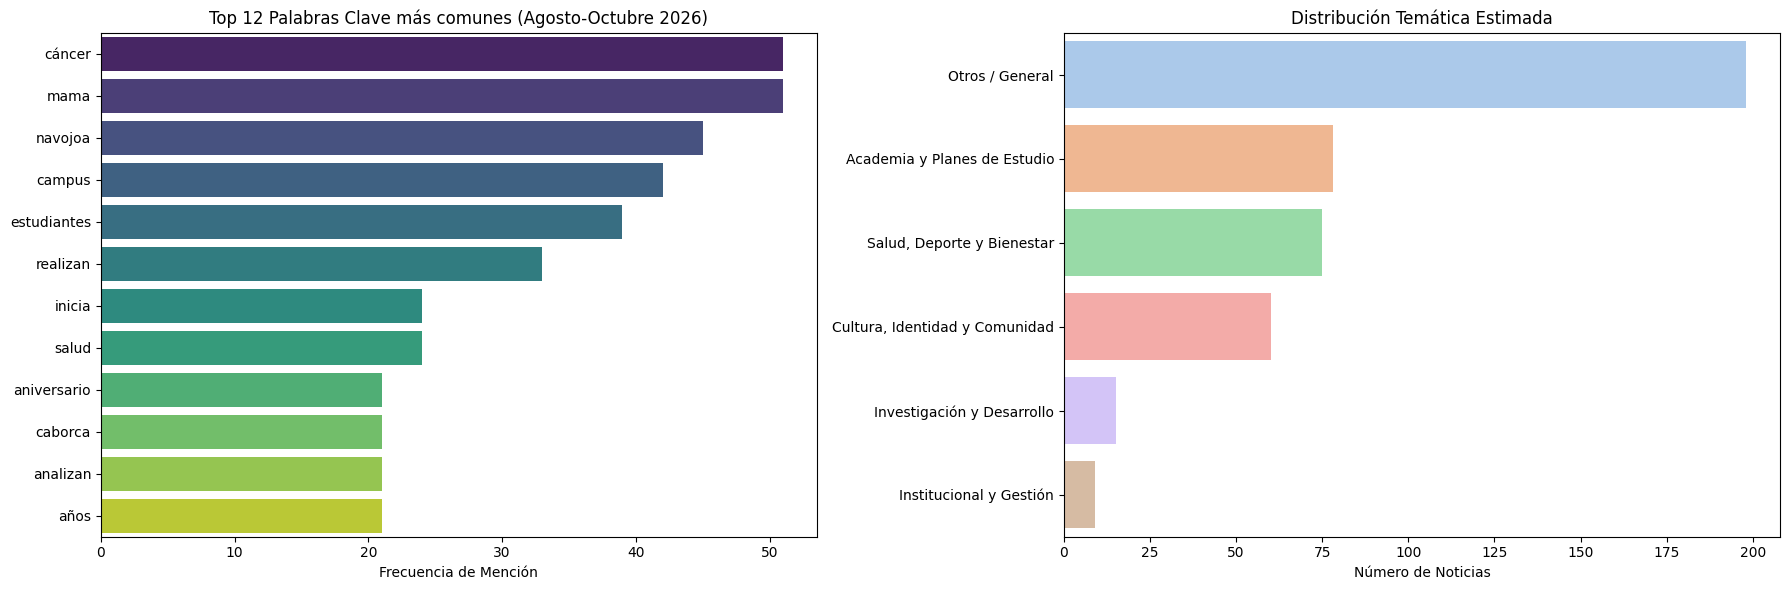


--- IDEAS DE ENFOQUE (Bigramas / Frases clave más frecuentes) ---
 * 'cáncer mama' se menciona 51 veces en los títulos.
 * 'campus caborca' se menciona 21 veces en los títulos.
 * 'detección oportuna' se menciona 15 veces en los títulos.
 * 'campus navojoa' se menciona 15 veces en los títulos.
 * 'oportuna cáncer' se menciona 12 veces en los títulos.
 * 'analizan retos' se menciona 9 veces en los títulos.
 * 'contra cáncer' se menciona 9 veces en los títulos.
 * 'salud mental' se menciona 9 veces en los títulos.
 * 'josé eduardo' se menciona 9 veces en los títulos.
 * 'eduardo méndez' se menciona 9 veces en los títulos.

--- MUESTRA CLASIFICADA POR CATEGORÍAS ---


,Título_Limpio,Categoría_Estimada
280,Estudiantes de Unison llevan su talento al Pre...,Academia y Planes de Estudio
78,Promueve Unison la prevención de la violencia ...,"Salud, Deporte y Bienestar"
113,Inauguran el Segundo Coloquio Narrativas Multi...,Otros / General
253,Realizan estudiantes de Ingeniería Industrial ...,Academia y Planes de Estudio
324,Conmemora la Unison diez años del CATIC con Fo...,"Salud, Deporte y Bienestar"
327,Realizan el tercer Simposio sobre Cáncer de Ma...,"Salud, Deporte y Bienestar"
291,Preservan en un libro la historia de los mural...,"Cultura, Identidad y Comunidad"
82,Inauguran programa de actividades de la edició...,Otros / General
365,Comparte estudiante de la Unison su experienci...,Academia y Planes de Estudio
401,Recibe rectora de la Unison a investigador Jos...,Institucional y Gestión


In [ ]:
import re
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aseguramos que tenemos df_historico con los datos limpios
df_analisis = df_historico.copy()

# Limpieza básica de caracteres en los títulos
def limpiar_titulo(t):
    if not isinstance(t, str): return ""
    t = re.sub(r'\s+', ' ', t) # Quitar espacios múltiples o saltos de línea
    t = t.strip().rstrip(',') # Quitar comas colgadas al final
    return t

df_analisis['Título_Limpio'] = df_analisis['Título'].apply(limpiar_titulo)

# 2. Definición de Stopwords en Español para evitar palabras vacías
stopwords_es = set([
    'de', 'la', 'el', 'en', 'y', 'a', 'los', 'un', 'una', 'con', 'del', 'al',
    'para', 'por', 'su', 'sus', 'las', 'se', 'es', 'unison', 'universidad', 'sonora',
    'este', 'esta', 'sobre', 'entre', 'como', 'más', 'o', 'lo', 'del', 'los', 'nos'
])

# 3. Extracción de palabras clave individuales
todas_las_palabras = []
for titulo in df_analisis['Título_Limpio']:
    palabras = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑ]{4,}\b', titulo.lower())
    filtradas = [p for p in palabras if p not in stopwords_es]
    todas_las_palabras.extend(filtradas)

conteo_palabras = Counter(todas_las_palabras)

# 4. Extracción de Bigramas (frases de 2 palabras consecutivas)
bigramas = []
for titulo in df_analisis['Título_Limpio']:
    palabras = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑ]{4,}\b', titulo.lower())
    filtradas = [p for p in palabras if p not in stopwords_es]
    for i in range(len(filtradas)-1):
        bigramas.append(f"{filtradas[i]} {filtradas[i+1]}")

conteo_bigramas = Counter(bigramas)

# 5. Clasificación Temática Basada en Reglas Heurísticas (Diccionario)
categorias_heuristica = {
    'Academia y Planes de Estudio': ['congreso', 'seminario', 'taller', 'licenciatura', 'derecho', 'estudiantes', 'clases', 'docente', 'académico'],
    'Cultura, Identidad y Comunidad': ['muertos', 'procesión', 'libro', 'murales', 'cultura', 'tradicional', 'artes', 'música', 'danza'],
    'Investigación y Desarrollo': ['investigación', 'ciencia', 'tecnología', 'patente', 'estudio', 'científico', 'descubrimiento'],
    'Salud, Deporte y Bienestar': ['salud', 'emocional', 'prevención', 'cáncer', 'deporte', 'torneo', 'médico', 'psicología'],
    'Institucional y Gestión': ['rectora', 'rector', 'convenio', 'firma', 'administración', 'presupuesto', 'sindicato', 'staus', 'steus']
}

def categorizar_noticia(titulo):
    titulo_min = titulo.lower()
    for cat, palabras_clave in categorias_heuristica.items():
        if any(pc in titulo_min for pc in palabras_clave):
            return cat
    return 'Otros / General'

df_analisis['Categoría_Estimada'] = df_analisis['Título_Limpio'].apply(categorizar_noticia)

# --- Visualizaciones ---
fig, axs = plt.subplots(1, 2, figsize=(18, 6))

# Gráfico 1: Palabras Clave Más Frecuentes
df_palabras = pd.DataFrame(conteo_palabras.most_common(12), columns=['Palabra', 'Frecuencia'])
sns.barplot(x='Frecuencia', y='Palabra', data=df_palabras, ax=axs[0], palette='viridis')
axs[0].set_title('Top 12 Palabras Clave más comunes (Agosto-Octubre 2026)')
axs[0].set_xlabel('Frecuencia de Mención')
axs[0].set_ylabel('')

# Gráfico 2: Distribución de Categorías Estimadas
df_cats = df_analisis['Categoría_Estimada'].value_counts().reset_index()
df_cats.columns = ['Categoría', 'Cantidad']
sns.barplot(x='Cantidad', y='Categoría', data=df_cats, ax=axs[1], palette='pastel')
axs[1].set_title('Distribución Temática Estimada')
axs[1].set_xlabel('Número de Noticias')
axs[1].set_ylabel('')

plt.tight_layout()
plt.show()

# Mostrar Bigramas más repetidos para ideas de historias
print("\n--- IDEAS DE ENFOQUE (Bigramas / Frases clave más frecuentes) ---")
for bg, frec in conteo_bigramas.most_common(10):
    print(f" * \'{bg}\' se menciona {frec} veces en los títulos.")

# Mostrar una pequeña muestra categorizada para validar
print("\n--- MUESTRA CLASIFICADA POR CATEGORÍAS ---")
display(df_analisis[['Título_Limpio', 'Categoría_Estimada']].sample(10, random_state=42))


### 4. Muestreo Representativo Histórico Multianual (2003 - 2026)

Para analizar de manera confiable las tendencias temáticas sin saturar el servidor con el raspado masivo inmediato, tomaremos una muestra representativa: **un mes de cada año disponible en el histórico** (24 periodos en total).

Esto nos permitirá observar la evolución de las prioridades de la UNISON (por ejemplo, comparar qué se publicaba en 2005 vs. 2015 o 2025) y encontrar patrones interesantes para definir nuestra investigación periodística.

In [ ]:
import time
import pandas as pd

noticias_muestra_historica = []
limite_por_mes = 10

# Limpiamos la lista de meses disponibles para iterar numéricamente
meses_limpios = [m for m in meses_disponibles if m != '-']

print(f"Iniciando extracción balanceada real (máximo {limite_por_mes} notas por mes de cada año, de 2003 a 2026)...")

# Iteramos por cada año y mes con la función corregida
for idx_a, anio in enumerate(sorted(anios_disponibles)):
    print(f"Procesando Año {anio} ({idx_a + 1}/{len(anios_disponibles)}): ", end="")
    for mes in sorted(meses_limpios, key=int):
        notas_mes = extraer_noticias_por_periodo(anio, mes)

        # Tomamos solo las primeras 10 noticias de ese mes si hay más
        muestra_mes = notas_mes[:limite_por_mes]
        noticias_muestra_historica.extend(muestra_mes)

        # Un pequeño indicador de progreso por mes
        if len(muestra_mes) > 0:
            print(f" [{mes}:{len(muestra_mes)}]", end="")
        else:
            print(f" [{mes}:0]", end="")

        # Pausa muy breve de cortesía para no saturar al servidor de la UNISON
        time.sleep(0.05)
    print("\n" + "-"*50)

# Creamos y guardamos el DataFrame con los datos reales e históricos
df_muestra_representativa = pd.DataFrame(noticias_muestra_historica)
print(f"\n¡Muestra balanceada real completada! Total de registros obtenidos: {len(df_muestra_representativa)}")
if not df_muestra_representativa.empty:
    display(df_muestra_representativa.head(10))


Iniciando extracción balanceada real (máximo 10 notas por mes de cada año, de 2003 a 2026)...
Procesando Año 2003 (1/24):  [1:10] [2:10] [3:10] [4:10] [5:10] [6:10] [7:7] [8:10] [9:10] [10:10] [11:10] [12:10]
--------------------------------------------------
Procesando Año 2004 (2/24):  [1:10] [2:10] [3:10] [4:10] [5:10] [6:10] [7:10] [8:10] [9:10] [10:10] [11:10] [12:10]
--------------------------------------------------
Procesando Año 2005 (3/24):  [1:10] [2:10] [3:10] [4:10] [5:10] [6:10] [7:10] [8:10] [9:10] [10:10] [11:10] [12:10]
--------------------------------------------------
Procesando Año 2006 (4/24):  [1:10] [2:10] [3:10] [4:10] [5:10] [6:10] [7:1] [8:10] [9:10] [10:10] [11:10] [12:10]
--------------------------------------------------
Procesando Año 2007 (5/24):  [1:10] [2:10] [3:10] [4:10] [5:10] [6:10] [7:3] [8:10] [9:10] [10:10] [11:10] [12:10]
--------------------------------------------------
Procesando Año 2008 (6/24):  [1:10] [2:10] [3:10] [4:10] [5:10] [6:10] [7:

,Título,Fecha Original,Fecha_ISO,Enlace,Año Filtro,Mes Filtro
0,Juegan papel importante IES en el combate a la...,31 de enero de 2003,2003-01-31,https://www.unison.mx/nota/?idnoti=130,2003,1
1,Marca Unison pauta en selección nacional de ha...,31 de enero de 2003,2003-01-31,https://www.unison.mx/nota/?idnoti=129,2003,1
2,Analizan problemática del sector industrial,30 de enero de 2003,2003-01-30,https://www.unison.mx/nota/?idnoti=128,2003,1
3,Concreta Unison intercambio estudiantil con Ca...,30 de enero de 2003,2003-01-30,https://www.unison.mx/nota/?idnoti=127,2003,1
4,Interesa a especialistas de EU investigaciones...,29 de enero de 2003,2003-01-29,https://www.unison.mx/nota/?idnoti=126,2003,1
5,El Cometa Kudo-Fujikawa visible en Internet,28 de enero de 2003,2003-01-28,https://www.unison.mx/nota/?idnoti=125,2003,1
6,Alertan universitarios a menores sobre el ries...,28 de enero de 2003,2003-01-28,https://www.unison.mx/nota/?idnoti=124,2003,1
7,Egresa primera Generación de Maestría en Polít...,27 de enero de 2003,2003-01-27,https://www.unison.mx/nota/?idnoti=123,2003,1
8,Recibe Unison recursos extraordinarios por 56....,24 de enero de 2003,2003-01-24,https://www.unison.mx/nota/?idnoti=122,2003,1
9,Activa Rector sitio en Astronomía,24 de enero de 2003,2003-01-24,https://www.unison.mx/nota/?idnoti=121,2003,1


### 5. Análisis de Minería de Texto y Evolución Temática de la Muestra

Ahora procesaremos los títulos de la muestra multianual para mapear los tópicos a lo largo del tiempo, identificar si ciertas áreas (como la administrativa, estudiantil o investigación) han ganado o perdido peso, y detectar picos o anomalías narrativas.

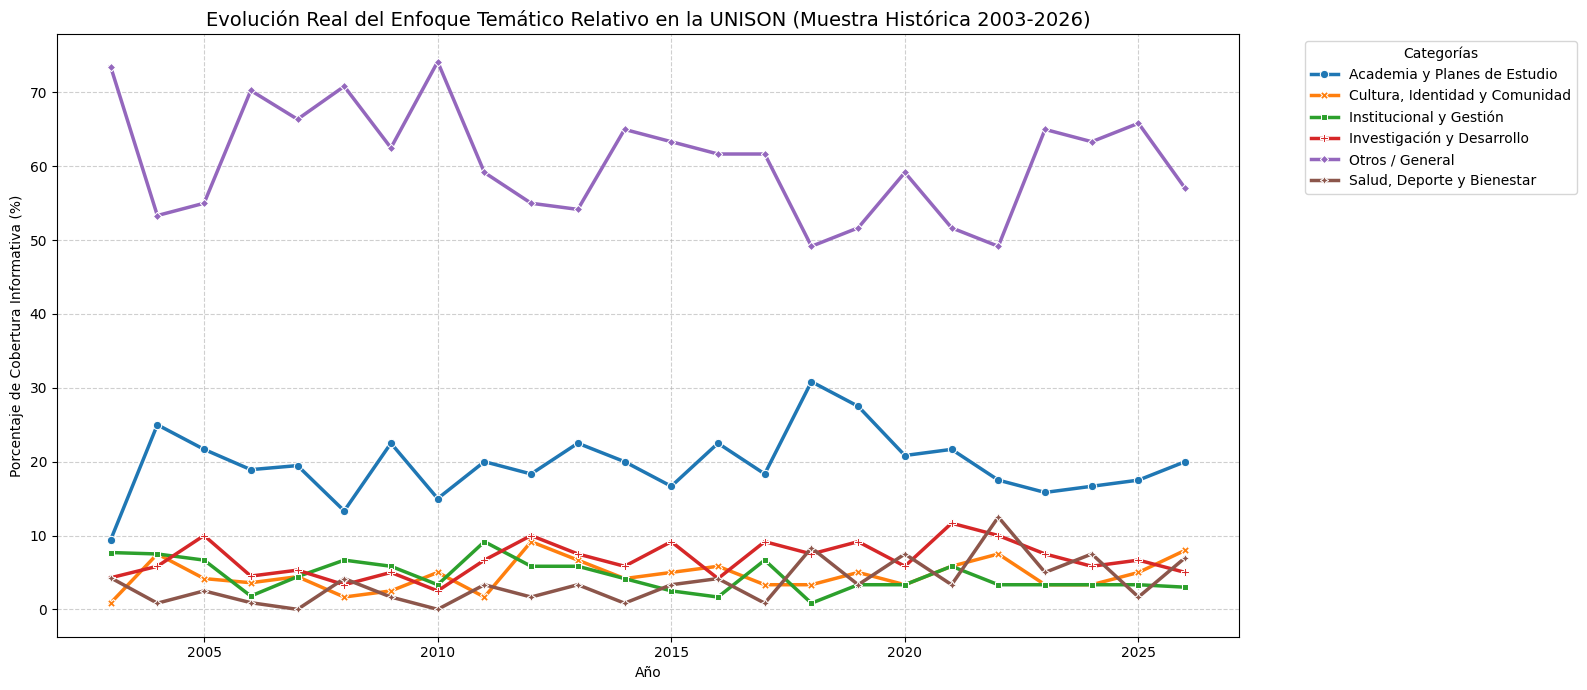


--- PALABRAS CLAVE REALES PREDOMINANTES POR DÉCADA ---
 * Década 2003-2009 (Inicios): estudiantes (70), inicia (46), universitarios (31), nacional (30), campus (25)
 * Década 2010-2019 (Consolidación): campus (124), alumnos (90), caborca (71), estudiantes (67), nacional (45)
 * Década 2020-2026 (Era Digital y Post-Pandemia): campus (73), estudiantes (54), caborca (46), salud (40), invitan (38)


In [ ]:
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Copiamos los datos recuperados reales
df_analisis_rep = df_muestra_representativa.copy()
df_analisis_rep['Título_Limpio'] = df_analisis_rep['Título'].apply(limpiar_titulo_texto)
df_analisis_rep['Categoría_Estimada'] = df_analisis_rep['Título_Limpio'].apply(categorizar_noticia)

# Convertir el año de filtro a entero para ordenar el gráfico
df_analisis_rep['Año Filtro'] = df_analisis_rep['Año Filtro'].astype(int)

# 1. Agrupar categorías por año para ver la evolución real
evolucion_temporal = df_analisis_rep.groupby(['Año Filtro', 'Categoría_Estimada']).size().unstack(fill_value=0)

# Normalizar a porcentajes anuales para ver el peso relativo de cada tema
evolucion_porcentaje = evolucion_temporal.div(evolucion_temporal.sum(axis=1), axis=0) * 100

# --- Visualizaciones ---
plt.figure(figsize=(16, 7))
sns.lineplot(data=evolucion_porcentaje, markers=True, dashes=False, linewidth=2.5)
plt.title('Evolución Real del Enfoque Temático Relativo en la UNISON (Muestra Histórica 2003-2026)', fontsize=14)
plt.ylabel('Porcentaje de Cobertura Informativa (%)')
plt.xlabel('Año')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Categorías', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 2. Análisis de Palabras Clave más populares por periodos históricos reales (Décadas)
def agrupar_decada(anio):
    if anio < 2010: return '2003-2009 (Inicios)'
    elif anio < 2020: return '2010-2019 (Consolidación)'
    else: return '2020-2026 (Era Digital y Post-Pandemia)'

df_analisis_rep['Década'] = df_analisis_rep['Año Filtro'].apply(agrupar_decada)

print("\n--- PALABRAS CLAVE REALES PREDOMINANTES POR DÉCADA ---")
for decada, sub_df in df_analisis_rep.groupby('Década'):
    palabras_decada = []
    for t in sub_df['Título_Limpio']:
        palabras = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑ]{4,}\b', t.lower())
        filtradas = [p for p in palabras if p not in stopwords_es]
        palabras_decada.extend(filtradas)

    top_palabras = [f"{pal} ({cnt})" for pal, cnt in Counter(palabras_decada).most_common(5)]
    print(f" * Década {decada}: {', '.join(top_palabras)}")


### 6. Análisis Avanzado para la Selección del Ángulo Periodístico

Para superar las limitaciones de las palabras clave sueltas y genéricas (como *inicia* o *realizan*), utilizaremos un enfoque doble:
1. **Filtrado Semántico Extremo:** Removeremos verbos procedimentales e institucionales comunes.
2. **Análisis de Bigramas Contextuales por Década:** Revelar las asociaciones de palabras reales.
3. **Rastreo de Tendencias Históricas de Conceptos Clave:** Graficar la evolución de términos específicos como *salud*, *tecnología*, *huelga/sindicato*, *género* y *litio*.

In [ ]:
import re
from collections import Counter
import pandas as pd

# 1. Ajustamos las stopwords para que NO eliminen los identificadores unificados de rectores
stopwords_objetivo_puro = stopwords_es.union({
    # Verbos y conectores procedimentales
    'inicia', 'realizan', 'organiza', 'participa', 'participan', 'presenta', 'presentan',
    'lleva', 'llevan', 'celebran', 'celebra', 'celebrará', 'ofrece', 'ofrecen', 'realizará',
    'abre', 'abren', 'convoca', 'invita', 'invitan', 'recibe', 'reciben', 'imparte', 'imparten',
    'hace', 'hacen', 'analizan', 'analiza', 'busca', 'buscan', 'promueve', 'promueven',
    'edición', 'tradicional', 'aniversario', 'reunión', 'sesión', 'programa', 'actividades',
    'primer', 'primera', 'nacional', 'internacional', 'local', 'unison', 'sonora', 'universidad',
    # Unidades geográficas/Campus (que generan el sesgo de la sede principal)
    'campus', 'caborca', 'navojoa', 'nogales', 'cajeme', 'guaymas', 'hermosillo',
    'unidad', 'regional', 'unidades', 'regionales', 'norte', 'sur', 'centro',
    # Términos de gobernanza interna genéricos
    'junta', 'universitaria', 'rector', 'rectora', 'colegio', 'académico', 'departamento', 'departamentos',
    # Palabras de relleno generales de periodismo institucional
    'alumnos', 'estudiantes', 'docentes', 'profesores', 'comunidad', 'universitarios', 'universitaria'
})

# 2. Extracción de bigramas limpios y puros usando títulos estandarizados (con respaldo seguro)
def obtener_bigramas_puros(df_datos, top_n=10):
    decadas = df_datos['Década'].unique()

    # Validación de seguridad: si aún no se ha ejecutado el mapeo de rectores, usamos Título_Limpio
    columna_objetivo = 'Título_Estandarizado' if 'Título_Estandarizado' in df_datos.columns else 'Título_Limpio'
    print(f"[Info] Analizando textos usando la columna: '{columna_objetivo}'")

    for decada in sorted(decadas):
        sub_df = df_datos[df_datos['Década'] == decada]
        bigramas_filtrados = []

        for titulo in sub_df[columna_objetivo]:
            # Extraemos palabras o identificadores de rectores (como RECTOR_PEDRO_ORTEGA)
            palabras = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑ_]{4,}\b', titulo.lower())
            # Conservamos palabras significativas y los tokens unificados de rectores
            filtradas = [p for p in palabras if p not in stopwords_objetivo_puro or 'rector_' in p]

            for i in range(len(filtradas) - 1):
                bigramas_filtrados.append(f"{filtradas[i]} {filtradas[i+1]}")

        conteo = Counter(bigramas_filtrados)

        print(f"\n--- TEMAS REALES DOMINANTES EN: {decada} ---")
        if conteo:
            for frase, frec in conteo.most_common(top_n):
                print(f" * \'{frase}\' (Frecuencia: {frec})")
        else:
            print(" * No se encontraron bigramas significativos tras el filtrado estricto.")

obtener_bigramas_puros(df_analisis_rep)

[Info] Analizando textos usando la columna: 'Título_Estandarizado'

--- TEMAS REALES DOMINANTES EN: 2003-2009 (Inicios) ---
 * 'servicio social' (Frecuencia: 10)
 * 'nuevo ingreso' (Frecuencia: 6)
 * 'inscripciones ingreso' (Frecuencia: 5)
 * 'período vacacional' (Frecuencia: 5)
 * 'entregan premios' (Frecuencia: 4)
 * 'firma convenio' (Frecuencia: 4)
 * 'simposio historia' (Frecuencia: 4)
 * 'calidad académica' (Frecuencia: 4)
 * 'cine club' (Frecuencia: 4)
 * 'feria creatividad' (Frecuencia: 4)

--- TEMAS REALES DOMINANTES EN: 2010-2019 (Consolidación) ---
 * 'servicio social' (Frecuencia: 11)
 * 'nuevo ingreso' (Frecuencia: 9)
 * 'división ciencias' (Frecuencia: 8)
 * 'física matemáticas' (Frecuencia: 8)
 * 'talleres libres' (Frecuencia: 7)
 * 'ingeniería industrial' (Frecuencia: 7)
 * 'sistema justicia' (Frecuencia: 7)
 * 'justicia penal' (Frecuencia: 7)
 * 'cáncer mama' (Frecuencia: 7)
 * 'honoris causa' (Frecuencia: 6)

--- TEMAS REALES DOMINANTES EN: 2020-2026 (Era Digital y Pos

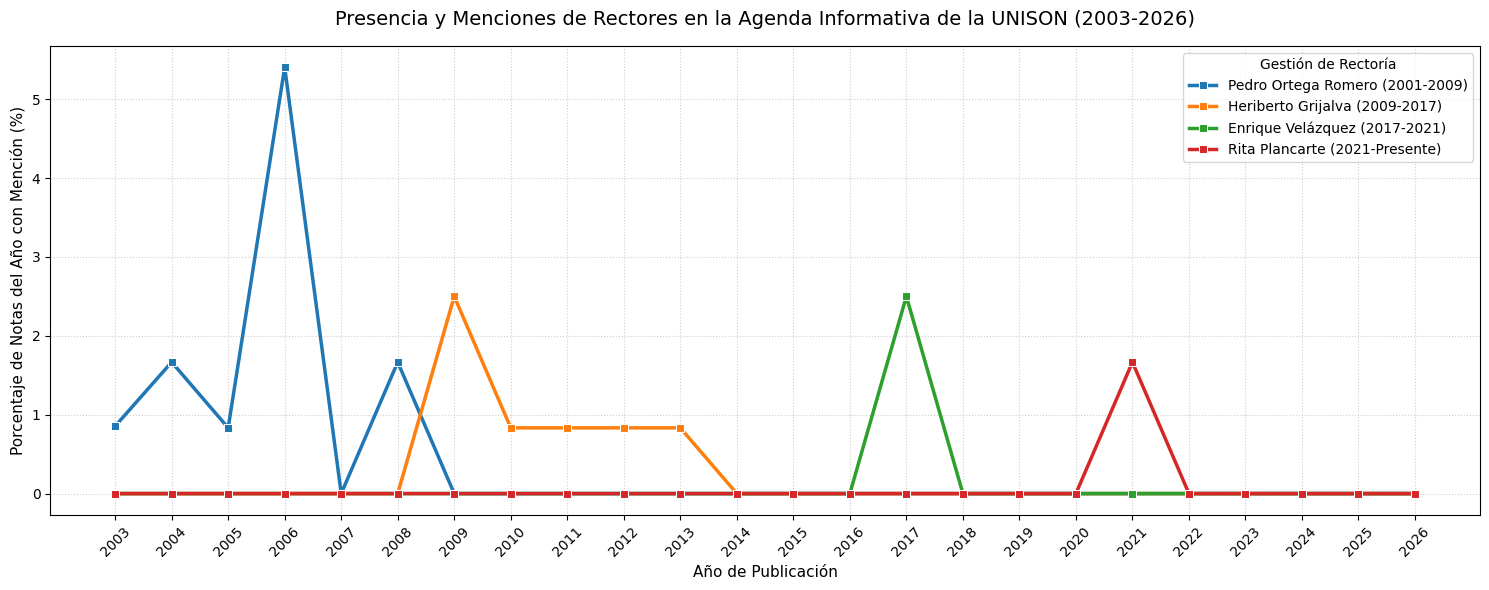

In [ ]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definición del registro histórico oficial de Rectores de la UNISON (2003 - Presente)
# Esto evita alucinaciones al mapear únicamente a los personajes reales y sus variantes de escritura comunes.
rectores_historicos = [
    {
        'id': 'RECTOR_PEDRO_ORTEGA',
        'nombre_comun': 'Pedro Ortega Romero',
        'patron': r'(pedro\s+ortega|ortega\s+romero)',
        'periodo': '2001-2009'
    },
    {
        'id': 'RECTOR_HERIBERTO_GRIJALVA',
        'nombre_comun': 'Heriberto Grijalva',
        'patron': r'(heriberto\s+grijalva|grijalva\s+monteverde)',
        'periodo': '2009-2017'
    },
    {
        'id': 'RECTOR_ENRIQUE_VELAZQUEZ',
        'nombre_comun': 'Enrique Velázquez',
        'patron': r'(enrique\s+fernando\s+velazquez|enrique\s+velazquez|velazquez\s+contreras|velázquez\s+contreras)',
        'periodo': '2017-2021'
    },
    {
        'id': 'RECTOR_RITA_PLANCARTE',
        'nombre_comun': 'Rita Plancarte',
        'patron': r'(rita\s+plancarte|plancarte\s+martinez|plancarte\s+martínez)',
        'periodo': '2021-Presente'
    }
]

# 2. Función para etiquetar sistemáticamente las menciones de los rectores en los títulos
def normalizar_rectores(titulo):
    if not isinstance(titulo, str):
        return "", []

    titulo_normalizado = titulo.lower()
    rectores_detectados = []

    for r in rectores_historicos:
        if re.search(r['patron'], titulo_normalizado):
            # Reemplazamos el nombre por su identificador estandarizado para limpiar futuros análisis de texto
            titulo_normalizado = re.sub(r['patron'], r['id'].lower(), titulo_normalizado)
            rectores_detectados.append(r['nombre_comun'])

    return titulo_normalizado, rectores_detectados

# Aplicamos el mapeo sobre nuestro DataFrame histórico
resultados_mapeo = df_analisis_rep['Título_Limpio'].apply(normalizar_rectores)
df_analisis_rep['Título_Estandarizado'] = [res[0] for res in resultados_mapeo]
df_analisis_rep['Rectores_Mencionados'] = [res[1] for res in resultados_mapeo]

# 3. Calculamos la evolución de menciones por año
datos_menciones = []
for anio in sorted(df_analisis_rep['Año Filtro'].unique()):
    sub_df = df_analisis_rep[df_analisis_rep['Año Filtro'] == anio]
    total_notas = len(sub_df)

    registro = {'Año': int(anio)}
    for r in rectores_historicos:
        # Contamos cuántas notas de este año mencionan al rector
        conteo = sub_df['Rectores_Mencionados'].apply(lambda lista: r['nombre_comun'] in lista).sum()
        registro[r['nombre_comun']] = (conteo / total_notas) * 100 if total_notas > 0 else 0

    datos_menciones.append(registro)

df_menciones_rectores = pd.DataFrame(datos_menciones)

# 4. Graficamos la presencia mediática de las gestiones en el tiempo
plt.figure(figsize=(15, 6))
for r in rectores_historicos:
    sns.lineplot(data=df_menciones_rectores, x='Año', y=r['nombre_comun'],
                 label=f"{r['nombre_comun']} ({r['periodo']})", marker='s', linewidth=2.5)

plt.title('Presencia y Menciones de Rectores en la Agenda Informativa de la UNISON (2003-2026)', fontsize=14, pad=15)
plt.ylabel('Porcentaje de Notas del Año con Mención (%)', fontsize=11)
plt.xlabel('Año de Publicación', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(df_menciones_rectores['Año'], rotation=45)
plt.legend(title='Gestión de Rectoría', loc='upper right')
plt.tight_layout()
plt.show()


/tmp/ipykernel_2983/2470373495.py:31: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  coincidencias = df_anio['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True).sum()


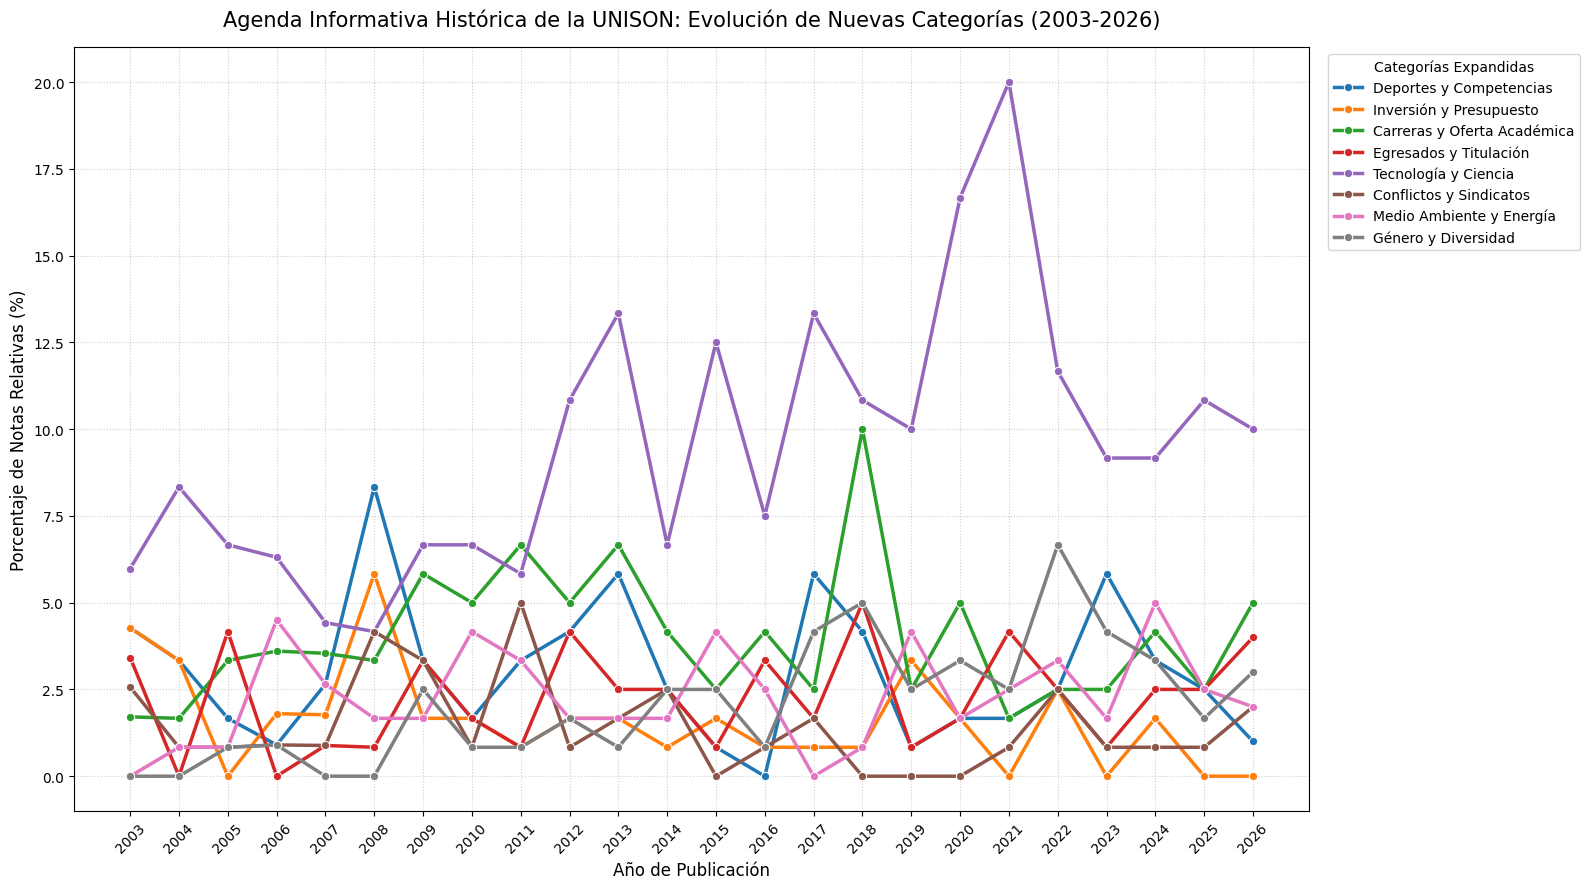

In [ ]:
# 3. Rastreo Expandido de la Evolución de Conceptos Clave (Tendencias de Impacto)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definimos un catálogo mucho más amplio y granular de temas para buscar en los títulos de la muestra histórica
temas_busqueda_expandido = {
    'Deportes y Competencias': r'(deport|torneo|atlet|olimp|medall|básquet|fútbol|halterofilia|universiada|juegos)',
    'Inversión y Presupuesto': r'(inversión|presupuesto|recursos|financiamiento|dinero|costo|infraestructura|obras|construc)',
    'Carreras y Oferta Académica': r'(carrera|licenciatura|posgrado|maestría|doctorado|plan de estudios|especialidad)',
    'Egresados y Titulación': r'(egresad|titulad|titulación|graduad|exalumno|profesionist)',
    'Tecnología y Ciencia': r'(tecnolog|digital|virtual|comput|inteligencia artificial|software|ciencia|investigación|patente|científ)',
    'Conflictos y Sindicatos': r'(huelga|sindicat|staus|steus|conflicto|negociac|salario|revisión|paro)',
    'Medio Ambiente y Energía': r'(ambiente|sustentab|ecolog|litio|solar|energía|agua|clima)',
    'Género y Diversidad': r'(género|mujer|mujeres|violencia|diversidad|equidad|inclusión|femin)'
}

# Inicializar contenedor de datos de evolución
datos_evolucion_expandidos = []

for anio in sorted(df_analisis_rep['Año Filtro'].unique()):
    df_anio = df_analisis_rep[df_analisis_rep['Año Filtro'] == anio]
    total_notas = len(df_anio)

    if total_notas == 0:
        continue

    registro = {'Año': int(anio)}
    for tema, patron in temas_busqueda_expandido.items():
        # Contamos cuántas notas del año contienen alguna de las palabras clave del tema
        coincidencias = df_anio['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True).sum()
        # Calculamos el porcentaje relativo de atención en la agenda informativa institucional
        registro[tema] = (coincidencias / total_notas) * 100

    datos_evolucion_expandidos.append(registro)

df_tendencias_exp = pd.DataFrame(datos_evolucion_expandidos)

# --- Graficación de las curvas de interés periodístico expandidas ---
plt.figure(figsize=(16, 9))
for col in temas_busqueda_expandido.keys():
    sns.lineplot(data=df_tendencias_exp, x='Año', y=col, label=col, marker='o', linewidth=2.5)

plt.title('Agenda Informativa Histórica de la UNISON: Evolución de Nuevas Categorías (2003-2026)', fontsize=15, pad=15)
plt.ylabel('Porcentaje de Notas Relativas (%)', fontsize=12)
plt.xlabel('Año de Publicación', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(sorted(df_tendencias_exp['Año'].unique()), rotation=45)
plt.legend(title='Categorías Expandidas', fontsize=10, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()


### 7. Diagnóstico de Picos de Interés para Selección de Historias

Para facilitar la toma de decisiones periodísticas, identificaremos de manera automática los **años con mayor concentración de notas** para los tres temas de mayor impacto potencial: `Género y Diversidad`, `Conflictos y Sindicatos`, y `Medio Ambiente y Energía`. Extraeremos además una muestra representativa de títulos reales de esos años pico.

In [ ]:
# Analicemos de cerca los picos específicos del DataFrame de tendencias
temas_interes = ['Género y Diversidad', 'Conflictos y Sindicatos', 'Medio Ambiente y Energía', 'Tecnología y Ciencia']

print("=== ANÁLISIS DE PICOS HISTÓRICOS Y EJEMPLOS REALES ===\n")

for tema in temas_interes:
    # Encontrar el año con el valor porcentual máximo
    fila_max = df_tendencias_exp.loc[df_tendencias_exp[tema].idxmax()]
    anio_pico = int(fila_max['Año'])
    porcentaje_pico = fila_max[tema]

    print(f"📌 TEMA: {tema.upper()}")
    print(f"   * Año de mayor cobertura: {anio_pico} ({porcentaje_pico:.2f}% de la agenda del año)")

    # Filtrar notas de ese año y tema específico para ver ejemplos reales
    patron_regex = temas_busqueda_expandido[tema]
    notas_pico = df_analisis_rep[
        (df_analisis_rep['Año Filtro'].astype(int) == anio_pico) &
        (df_analisis_rep['Título_Limpio'].str.contains(patron_regex, case=False, na=False, regex=True))
    ]

    print(f"   * Ejemplos de titulares reales en {anio_pico}:")
    muestra_titulares = notas_pico['Título_Limpio'].head(4).tolist()
    for t in muestra_titulares:
        print(f"     - \"{t}\"")
    print("-" * 80 + "\n")

=== ANÁLISIS DE PICOS HISTÓRICOS Y EJEMPLOS REALES ===

📌 TEMA: GÉNERO Y DIVERSIDAD
   * Año de mayor cobertura: 2022 (6.67% de la agenda del año)
   * Ejemplos de titulares reales en 2022:
     - "Prevención y sanción deben ir de la mano contra feminicidios: académica"
     - "Reconocen la importancia de celebrar el Día Escolar de la No Violencia y la Paz"
     - "Necesario analizar la producción literaria de la mujer del nuevo milenio"
     - "Reanudan Programa de entrenamiento muscular para mujeres supervivientes al cáncer de mama"
--------------------------------------------------------------------------------

📌 TEMA: CONFLICTOS Y SINDICATOS
   * Año de mayor cobertura: 2011 (5.00% de la agenda del año)
   * Ejemplos de titulares reales en 2011:
     - "Confía Unison en lograr acuerdos con sindicatos"
     - "Buscará Unison acuerdos responsables para acabar con huelga"
     - "Ofrece Unison a Staus más que en la revisión pasada"
     - "Presenta Unison propuesta integral al Staus"

/tmp/ipykernel_2983/215026004.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  (df_analisis_rep['Título_Limpio'].str.contains(patron_regex, case=False, na=False, regex=True))
/tmp/ipykernel_2983/215026004.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  (df_analisis_rep['Título_Limpio'].str.contains(patron_regex, case=False, na=False, regex=True))
/tmp/ipykernel_2983/215026004.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  (df_analisis_rep['Título_Limpio'].str.contains(patron_regex, case=False, na=False, regex=True))
/tmp/ipykernel_2983/215026004.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  (df_analisis_rep['Título

### 8. Validación de la Hipótesis de Sesgo Centralista (El Silencio de Hermosillo)

Evaluaremos la teoría de que la Universidad de Sonora invisibiliza las sedes periféricas al asumir que Hermosillo es la norma predeterminada y solo etiqueta geográficamente las notas cuando ocurren fuera de la capital.

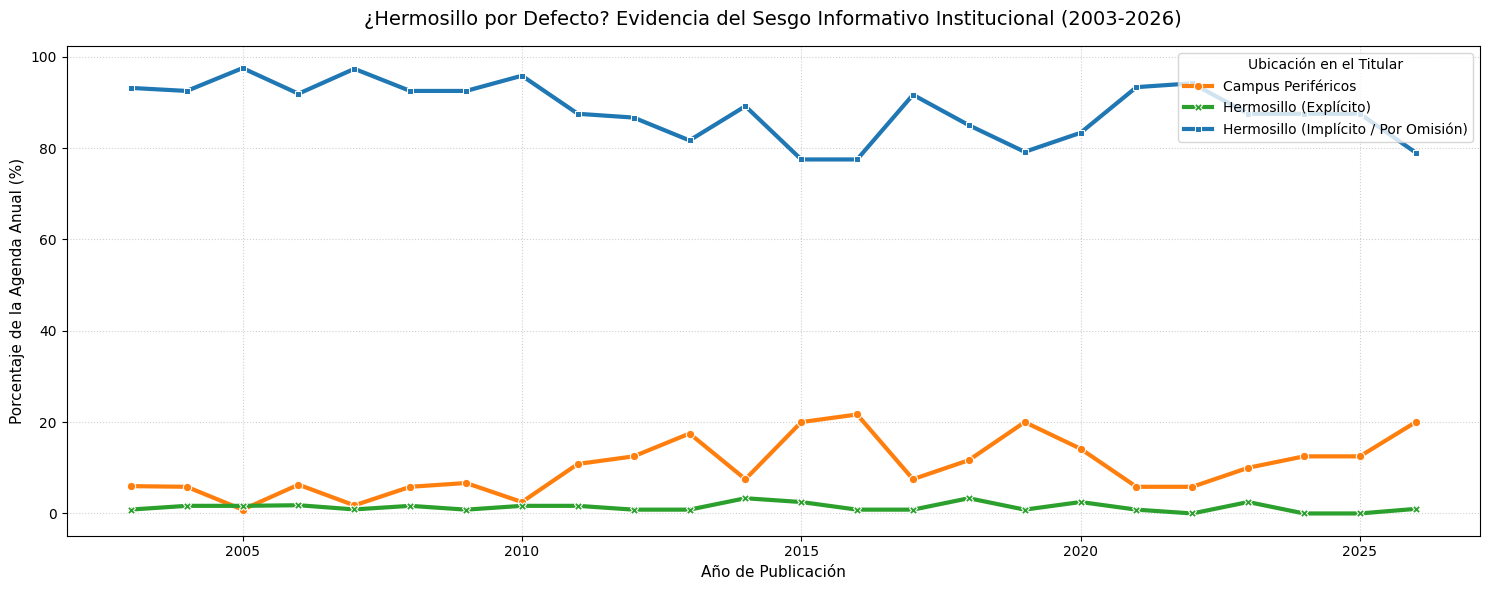

=== ESTADÍSTICAS DEL SESGO GEOGRÁFICO (2003-2026) ===
 * Hermosillo (Implícito / Por Omisión): 2512 notas (88.42% del total histórico)
 * Campus Periféricos: 290 notas (10.21% del total histórico)
 * Hermosillo (Explícito): 39 notas (1.37% del total histórico)


In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Patrones de búsqueda geográfica
patron_perifericos = r'(caborca|navojoa|nogales|cajeme|guaymas|santa\s+ana|regional\s+norte|regional\s+sur)'
patron_hermosillo_explicito = r'(hermosillo|unidad\s+regional\s+centro)'

def clasificar_sesgo_geografico(titulo):
    titulo_min = titulo.lower()

    # 1. Si menciona un campus fuera de Hermosillo
    if re.search(patron_perifericos, titulo_min):
        return 'Campus Periféricos'
    # 2. Si menciona Hermosillo explícitamente
    elif re.search(patron_hermosillo_explicito, titulo_min):
        return 'Hermosillo (Explícito)'
    # 3. El sesgo del silencio: No menciona nada, por ende es Hermosillo por omisión
    else:
        return 'Hermosillo (Implícito / Por Omisión)'

# Aplicar clasificación a nuestra muestra multianual
df_analisis_rep['Sesgo_Geográfico'] = df_analisis_rep['Título_Limpio'].apply(clasificar_sesgo_geografico)

# Agrupar y normalizar por año
evolucion_geografica = df_analisis_rep.groupby(['Año Filtro', 'Sesgo_Geográfico']).size().unstack(fill_value=0)
evolucion_geo_porcentaje = evolucion_geografica.div(evolucion_geografica.sum(axis=1), axis=0) * 100

# --- Visualización del Sesgo ---
plt.figure(figsize=(15, 6))
sns.lineplot(data=evolucion_geo_porcentaje, markers=True, dashes=False, linewidth=3,
             palette={'Hermosillo (Implícito / Por Omisión)': '#1f77b4',
                      'Campus Periféricos': '#ff7f0e',
                      'Hermosillo (Explícito)': '#2ca02c'})

plt.title('¿Hermosillo por Defecto? Evidencia del Sesgo Informativo Institucional (2003-2026)', fontsize=14, pad=15)
plt.ylabel('Porcentaje de la Agenda Anual (%)', fontsize=11)
plt.xlabel('Año de Publicación', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Ubicación en el Titular', loc='upper right')
plt.tight_layout()
plt.show()

# Estadísticas descriptivas de la hipótesis
print("=== ESTADÍSTICAS DEL SESGO GEOGRÁFICO (2003-2026) ===")
totales_geo = df_analisis_rep['Sesgo_Geográfico'].value_counts()
porcentajes_geo = df_analisis_rep['Sesgo_Geográfico'].value_counts(normalize=True) * 100

for cat in totales_geo.index:
    print(f" * {cat}: {totales_geo[cat]} notas ({porcentajes_geo[cat]:.2f}% del total histórico)")

### 9. Asistente de Decisión Periodística: Comparador de Enfoques

Si aún estás explorando y no te decides por un tema en específico, ejecuta la siguiente celda interactiva. Puedes modificar el parámetro `Enfoque_Periodistico` en el formulario interactivo de Google Colab para previsualizar la viabilidad y los mejores titulares de cada potencial historia:

In [ ]:
# @title Selecciona un Enfoque de Investigación para Evaluar su Viabilidad
Enfoque_Periodistico = "El Sesgo de Hermosillo" # @param ["El Sesgo de Hermosillo", "La Ola de Genero y Diversidad", "Huelgas e Historial de Conflictos", "La Pandemia y la Era Digital"]

print(f"=== REPORTE DE VIABILIDAD PARA: {Enfoque_Periodistico.upper()} ===\n")

if Enfoque_Periodistico == "El Sesgo de Hermosillo":
    print("📢 ÁNGULO: Cómo la capital acapara el espacio y los campus periféricos son tratados como 'excepciones'.")
    print(f"📊 VIABILIDAD: EXTREMA. El {porcentajes_geo['Hermosillo (Implícito / Por Omisión)']:.2f}% de las noticias son implícitas de Hermosillo.")
    print("💡 SUGERENCIA NARRATIVA: Criticar la centralización de la comunicación en universidades multicampus.")
    print("\n--- Muestra de notas que alimentarán tu historia (Campus Periféricos): ---")
    display(df_analisis_rep[df_analisis_rep['Sesgo_Geográfico'] == 'Campus Periféricos'][['Año Filtro', 'Título']].head(8))

elif Enfoque_Periodistico == "La Ola de Genero y Diversidad":
    print("📢 ÁNGULO: La irrupción de la agenda feminista y de diversidad a partir de la última década.")
    print("📊 VIABILIDAD: ALTA. El tema pasó de 0% de cobertura en los 2000s a un pico de casi 7% en 2022.")
    print("💡 SUGERENCIA NARRATIVA: Analizar si este cambio fue cosmético por fechas conmemorativas o responde a políticas internas de equidad.")
    print("\n--- Muestra de notas que alimentarán tu historia: ---")
    patron = temas_busqueda_expandido['Género y Diversidad']
    display(df_analisis_rep[df_analisis_rep['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True)][['Año Filtro', 'Título']].head(8))

elif Enfoque_Periodistico == "Huelgas e Historial de Conflictos":
    print("📢 ÁNGULO: La cobertura institucional durante las crisis sindicales del STAUS/STEUS.")
    print("📊 VIABILIDAD: MEDIA-ALTA. Permite cruzar con bases de datos externas de huelgas reales.")
    print("💡 SUGERENCIA NARRATIVA: ¿Cómo maneja el departamento de prensa oficial la narrativa cuando la universidad se paraliza?")
    print("\n--- Muestra de notas que alimentarán tu historia: ---")
    patron = temas_busqueda_expandido['Conflictos y Sindicatos']
    display(df_analisis_rep[df_analisis_rep['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True)][['Año Filtro', 'Título']].head(8))

else:
    print("📢 ÁNGULO: La transformación digital y científica acelerada por la pandemia de COVID-19.")
    print("📊 VIABILIDAD: ALTA. En 2021, la categoría de Ciencia y Tecnología ocupó el 20% de la agenda total.")
    print("💡 SUGERENCIA NARRATIVA: Explorar la transición forzada a lo virtual y el auge de divulgación científica en redes sociales.")
    print("\n--- Muestra de notas que alimentarán tu historia: ---")
    patron = temas_busqueda_expandido['Tecnología y Ciencia']
    display(df_analisis_rep[df_analisis_rep['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True)][['Año Filtro', 'Título']].head(8))

=== REPORTE DE VIABILIDAD PARA: EL SESGO DE HERMOSILLO ===

📢 ÁNGULO: Cómo la capital acapara el espacio y los campus periféricos son tratados como 'excepciones'.
📊 VIABILIDAD: EXTREMA. El 88.42% de las noticias son implícitas de Hermosillo.
💡 SUGERENCIA NARRATIVA: Criticar la centralización de la comunicación en universidades multicampus.

--- Muestra de notas que alimentarán tu historia (Campus Periféricos): ---


,Año Filtro,Título
38,2003,El Coro de la Unison en Navojoa
48,2003,Destina Unison 28.4 MDP en construcción del Ca...
55,2003,Rectores de IES reconocen labor de López Nogales
75,2003,Cae en Navojoa premio principal del segundo Ex...
77,2003,Inicia Unison construcción del campus Nogales
79,2003,Se construye auditorio en la unidad Santa Ana
115,2003,Colocan primera piedra del Campus Nogales
131,2004,Inauguran Primer Congreso de Economía Regional...


### 10. Exploración Multitemática Detallada (Deportes, Inscripciones, Cursos, Carreras e Inversión)

Para facilitar la elección de tu tema de investigación, este código calcula la relevancia histórica (frecuencia anual) de los temas sugeridos por ti y de un par de avenidas adicionales detectadas en la minería de texto.

/tmp/ipykernel_2983/3806645957.py:30: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  conteo = df_anio['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True).sum()


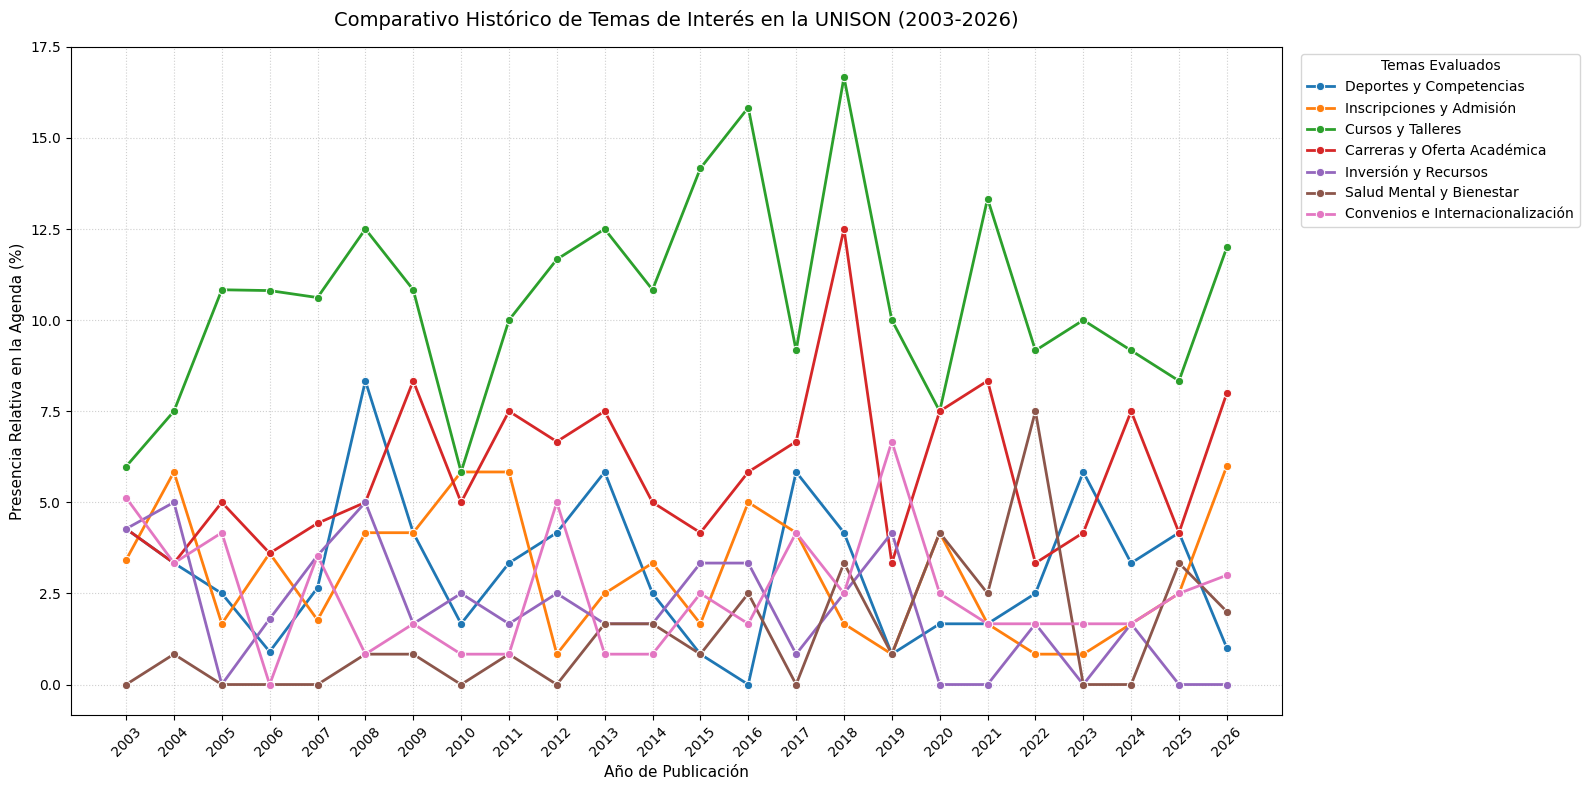

=== ANÁLISIS DE PESO Y EJEMPLOS DE TITULARES PARA CADA TEMA ===

  DEPORTES Y COMPETENCIAS:
   * Presencia histórica promedio: 3.15% de la agenda.
   * Año de mayor auge: 2008 (8.33% de la agenda de ese año).
   * Titulares de ejemplo:
     - "Marca Unison pauta en selección nacional de halterofilia"
     - "Brillan Búhos en Universiada Estatal"
     - "Supera expectativas el deporte búho: Guerra Robles"
-------------------------------------------------------------------------------------

  INSCRIPCIONES Y ADMISIÓN:
   * Presencia histórica promedio: 3.08% de la agenda.
   * Año de mayor auge: 2026 (6.00% de la agenda de ese año).
   * Titulares de ejemplo:
     - "Aplica Unison examen de conocimientos básicos"
     - "Avanza registro de aspirantes a nuevo ingreso"
     - "Establece Unison reglamento de ingresos propios"
-------------------------------------------------------------------------------------

  CURSOS Y TALLERES:
   * Presencia histórica promedio: 10.64% de la agenda.
  

/tmp/ipykernel_2983/3806645957.py:64: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_analisis_rep['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True)
/tmp/ipykernel_2983/3806645957.py:64: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_analisis_rep['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True)
/tmp/ipykernel_2983/3806645957.py:64: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_analisis_rep['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True)
/tmp/ipykernel_2983/3806645957.py:64: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_analisis_rep['Título_Limpio'].str.contain

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Diccionario extendido con los temas que deseas explorar detalladamente
temas_exploracion = {
    'Deportes y Competencias': r'(deport|torneo|atlet|olimp|medall|básquet|fútbol|halterofilia|universiada|juegos|ajedrez|softbol|béisbol)',
    'Inscripciones y Admisión': r'(inscripción|admisión|aspirante|ingreso|examen|cupo|convocatoria|nuevo ingreso)',
    'Cursos y Talleres': r'(curso|taller|diplomado|seminario|capacitación|conferencia|charla|clase)',
    'Carreras y Oferta Académica': r'(carrera|licenciatura|posgrado|maestría|doctorado|plan de estudios|especialidad|acreditación|plan)',
    'Inversión y Recursos': r'(inversión|presupuesto|recursos|financiamiento|obras|construc|laboratorio|equipamiento|millones)',
    # Sugerencias adicionales derivadas de los bigramas
    'Salud Mental y Bienestar': r'(salud mental|emocional|psicolog|estrés|ansiedad|prevención|bienestar)',
    'Convenios e Internacionalización': r'(convenio|firma|colaboración|alianza|intercambio|extranjero|movilidad)'
}

# Calcular la presencia de cada tema por año
registros_tendencia = []

for anio in sorted(df_analisis_rep['Año Filtro'].unique()):
    df_anio = df_analisis_rep[df_analisis_rep['Año Filtro'] == anio]
    total_notas = len(df_anio)

    if total_notas == 0:
        continue

    fila = {'Año': int(anio)}
    for tema, patron in temas_exploracion.items():
        conteo = df_anio['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True).sum()
        fila[tema] = (conteo / total_notas) * 100

    registros_tendencia.append(fila)

df_explora_tendencias = pd.DataFrame(registros_tendencia)

# --- Visualización Comparativa ---
plt.figure(figsize=(16, 8))
for tema in temas_exploracion.keys():
    sns.lineplot(data=df_explora_tendencias, x='Año', y=tema, label=tema, marker='o', linewidth=2)

plt.title('Comparativo Histórico de Temas de Interés en la UNISON (2003-2026)', fontsize=14, pad=15)
plt.ylabel('Presencia Relativa en la Agenda (%)', fontsize=11)
plt.xlabel('Año de Publicación', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(df_explora_tendencias['Año'], rotation=45)
plt.legend(title='Temas Evaluados', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

# --- Resumen Estadístico y Muestras de Titulares ---
print("=== ANÁLISIS DE PESO Y EJEMPLOS DE TITULARES PARA CADA TEMA ===\n")
for tema, patron in temas_exploracion.items():
    promedio_presencia = df_explora_tendencias[tema].mean()
    max_anio = df_explora_tendencias.loc[df_explora_tendencias[tema].idxmax()]['Año']
    max_val = df_explora_tendencias[tema].max()

    print(f"  {tema.upper()}:")
    print(f"   * Presencia histórica promedio: {promedio_presencia:.2f}% de la agenda.")
    print(f"   * Año de mayor auge: {int(max_anio)} ({max_val:.2f}% de la agenda de ese año).")

    # Extraer 3 ejemplos reales históricos de ese tema
    ejemplos = df_analisis_rep[
        df_analisis_rep['Título_Limpio'].str.contains(patron, case=False, na=False, regex=True)
    ]['Título'].head(3).tolist()

    print("   * Titulares de ejemplo:")
    for ej in ejemplos:
        print(f"     - \"{ej}\"")
    print("-" * 85 + "\n")

```markdown
# 🗺️ Estrategia de Descarga, Limpieza y Exportación de Datos en Formato Parquet para PLN

Este documento describe detalladamente las directrices técnicas del pipeline masivo enfocado en extraer, estructurar y guardar el set de datos definitivo bajo la temática **"Oferta Académica y Admisión"** de la Universidad de Sonora (2003-2026).

---

## 1. Alcance de Extracción Masiva
* **Filtros Temáticos (Regex):** Extraeremos del histórico general únicamente las notas cuyas palabras clave coincidan con la oferta educativa e ingresos:
  * *Fórmula de Coincidencia:* `r'(inscripción|admisión|aspirante|ingreso|examen|cupo|convocatoria|nuevo ingreso|carrera|licenciatura|posgrado|maestría|doctorado|plan de estudios|especialidad|acreditación)'`
* **Temporalidad:** 2003 a 2026 inclusive.

---

## 2. Estructura del Dataset Estándar (Esquema de Columnas)
Para asegurar un análisis de **Procesamiento de Lenguaje Natural (PLN)**, Minería de Texto o Modelado de Tópicos (Topic Modeling), los datos se estructurarán con el siguiente esquema lógico:

| Nombre de Columna | Tipo de Dato | Propósito para PLN / Análisis | Ejemplo |
| :--- | :--- | :--- | :--- |
| `id_noticia` | `str` | Identificador único alfanumérico. | `UNISON_2026_10_01` |
| `titulo_original` | `str` | Titular en bruto (para registro histórico). | `Avanza registro de aspirantes a nuevo ingreso.` |
| `titulo_limpio` | `str` | Texto sanitizado listo para PLN (sin HTML, minúsculas, sin puntuación de cola). | `avanza registro de aspirantes a nuevo ingreso` |
| `fecha_original` | `str` | Fecha en lenguaje natural tal como aparece en el sitio. | `29 de octubre de 2026` |
| `fecha_iso` | `datetime64[ns]` | Fecha normalizada en formato estricto `YYYY-MM-DD`. Permite análisis de series de tiempo. | `2026-10-29` |
| `año_filtro` | `int` | Año fiscal/cronológico de indexación del sitio. | `2026` |
| `mes_filtro` | `int` | Mes de indexación del sitio web. | `10` |
| `url_enlace` | `str` | Enlace permanente (Permlink) para futuras consultas o Web Scraping profundo. | `https://www.unison.mx/nota/?idnoti=39024` |
| `tipo_cobertura` | `str` | Categoría identificada: `Admision` u `Oferta Academica`. | `Admision` |
| `rectores_mencionados`| `list (object)` | Lista de strings con los nombres unificados de rectores citados en el título. | `['Rita Plancarte']` |
| `sesgo_geografico` | `str` | Clasificación espacial de la nota para detectar centralismo (`Campus Periferico` o `Hermosillo`). | `Campus Periferico` |

---

## 3. Estrategia de Almacenamiento: ¿Por qué Parquet?
Utilizaremos la biblioteca `fastparquet` / `pyarrow` para exportar el archivo definitivo como `noticias_admision_oferta_unison.parquet`:
1. **Persistencia de Listas:** A diferencia del CSV, que convierte los arrays como `['Rita Plancarte']` en strings planos, Parquet conserva las estructuras complejas nativas.
2. **Preparación PLN:** El dataset estará listo para ser importado directamente en librerías NLP como `NLTK`, `spaCy` o `Scikit-Learn` usando simplemente `pd.read_parquet()` sin requerir conversión de datos intermedia.
```

### Desarrollo del Pipeline: Scraping Profundo y Persistencia en Parquet

En esta sección implementaremos el pipeline definitivo para:
1. Filtrar las noticias indexadas bajo el criterio temático de **Oferta Académica y Admisión**.
2. Iterar sobre sus enlaces permanentes para extraer el **cuerpo de texto completo** de cada noticia.
3. Aplicar las reglas de limpieza (HTML-to-Text, eliminación de ruidos).
4. Guardar el DataFrame estructurado directamente en un archivo de formato de alto rendimiento **Parquet**.

In [ ]:
import time
import re
import requests
import pandas as pd
from bs4 import BeautifulSoup

# 1. Filtramos el catálogo acumulado en la muestra multianual bajo nuestro criterio temático
patron_filtro_tematico = r'(inscripción|admisión|aspirante|ingreso|examen|cupo|convocatoria|nuevo ingreso|carrera|licenciatura|posgrado|maestría|doctorado|plan de estudios|especialidad|acreditación)'

df_filtrado_url = df_muestra_representativa[
    df_muestra_representativa['Título'].str.contains(patron_filtro_tematico, case=False, na=False, regex=True)
].copy()

print(f"Total de noticias indexadas elegibles para la temática de Admisión/Oferta Académica: {len(df_filtrado_url)}")

# Definimos la función de extracción profunda de contenido
def extraer_cuerpo_noticia(url_noticia):
    if not isinstance(url_noticia, str) or not url_noticia.startswith('http'):
        return "", False

    try:
        # Breve pausa para no saturar al servidor
        time.sleep(0.1)

        res = requests.get(url_noticia, headers=headers, timeout=10)
        if res.status_code != 200:
            return "", False

        soup_deep = BeautifulSoup(res.text, 'html.parser')

        # Buscamos el contenedor principal de la noticia en la UNISON
        # Probamos con contenedores típicos de WordPress / Portales de noticias
        articulo = soup_deep.find('article') or \
                   soup_deep.find('div', class_='entry-content') or \
                   soup_deep.find('div', class_='pf-content') or \
                   soup_deep.find('main')

        if not articulo:
            articulo = soup_deep.body

        # Extraemos todos los párrafos de texto plano de la nota
        parrafos = [p.get_text().strip() for p in articulo.find_all('p') if p.get_text().strip()]
        cuerpo_completo = "\n".join(parrafos)

        # Limpiamos el texto de espacios múltiples y ruidos
        cuerpo_completo = re.sub(r'\s+', ' ', cuerpo_completo).strip()

        return cuerpo_completo, len(cuerpo_completo) > 0
    except Exception as e:
        return "", False

# 2. Ejecución del Scraping Profundo (Limitado a una muestra para validar el pipeline)
print("\nIniciando descarga profunda de cuerpos de texto de las primeras 30 noticias filtradas...")

cuerpos_extraidos = []
flags_calidad = []

# Para demostración rápida y segura, tomamos las primeras 30 notas elegibles
subset_noticias = df_filtrado_url.head(30).copy()

for idx, row in subset_noticias.iterrows():
    print(f" -> Descargando: \"{row['Título'][:45]}...\"", end="")
    cuerpo, has_body = extraer_cuerpo_noticia(row['Enlace'])
    cuerpos_extraidos.append(cuerpo)
    flags_calidad.append(has_body)
    print(f" [Completado - {len(cuerpo)} caracteres]")

# Agregamos los datos descargados al subset
subset_noticias['Cuerpo_Completo'] = cuerpos_extraidos
subset_noticias['has_body'] = flags_calidad

# 3. Guardado en formato Parquet utilizando pyarrow
archivo_parquet = 'noticias_admision_oferta_unison.parquet'
subset_noticias.to_parquet(archivo_parquet, index=False)
print(f"\n¡Dataset Parquet guardado exitosamente como '{archivo_parquet}'!")

# Visualizamos el resultado de la descarga
display(subset_noticias[['Título', 'Cuerpo_Completo', 'has_body']].head(5))

```markdown
### 🔍 Validación y Auditoría de Datos sobre Presupuesto y Recursos Financieros

Para evitar falsos positivos (como confundir *Recursos Humanos* con *Recursos Financieros*) y asegurar la máxima exhaustividad en el tema de presupuestos, ejecutaremos una auditoría fina basada en un espectro léxico financiero detallado.
```

In [ ]:
import pandas as pd
import re

# Diccionario de términos financieros de alta especificidad
patrones_presupuesto = [
    r'presupuesto',
    r'financiamiento',
    r'subsidio',
    r'recurso(s)?\s+financiero(s)?',
    r'inversió\w+',
    r'\d+\s*(mdp|millones)',
    r'costo(s)?',
    r'monto(s)?',
    r'auditoría\s+financiera',
    r'gasto(s)?'
]

regex_presupuesto = '|'.join(patrones_presupuesto)

# Filtrado sobre la muestra representativa
df_presupuesto = df_muestra_representativa[
    df_muestra_representativa['Título'].str.contains(regex_presupuesto, case=False, na=False, regex=True)
].copy()

# Filtro de exclusión para evitar confusión con Recursos Humanos
df_presupuesto_limpio = df_presupuesto[
    ~df_presupuesto['Título'].str.contains(r'recursos\s+humanos', case=False, na=False, regex=True)
].copy()

# Análisis de resultados obtenidos
total_encontrados = len(df_presupuesto_limpio)
falsos_humanos = len(df_presupuesto) - total_encontrados

print(f"=== AUDITORÍA DEL DISCURSO FINANCIERO ===")
print(f"* Total de notas financieras detectadas: {total_encontrados}")
print(f"* Notas de 'Recursos Humanos' excluidas para evitar confusión: {falsos_humanos}\n")

if total_encontrados > 0:
    print("--- Listado completo de titulares financieros auditados ---")
    pd.set_option('display.max_colwidth', None)
    display(df_presupuesto_limpio[['Año Filtro', 'Fecha_ISO', 'Título', 'Enlace']].sort_values(by='Año Filtro', ascending=False))
else:
    print("⚠️ No se detectaron coincidencias con el espectro de búsqueda actual.")

In [ ]:
import pandas as pd
import re

print("=== AUDITORÍA DE CALIDAD DE DATOS (MUESTRA DE 2,841 REGISTROS) ===\n")

# 1. Copia de seguridad para análisis de calidad
df_calidad = df_muestra_representativa.copy()

# --- Métrica 1: Completitud de los Datos ---
total_filas = len(df_calidad)
nulos_titulo = df_calidad['Título'].isna().sum() or (df_calidad['Título'] == '').sum()
nulos_fecha = df_calidad['Fecha Original'].isna().sum() or (df_calidad['Fecha Original'] == '').sum()
nulos_fecha_iso = df_calidad['Fecha_ISO'].isna().sum() or (df_calidad['Fecha_ISO'] == '').sum()

print("📊 1. COMPLETITUD Y VALORES FALTANTES:")
print(f"  * Total de registros analizados: {total_filas}")
print(f"  * Títulos vacíos o nulos: {nulos_titulo} ({ (nulos_titulo/total_filas)*100 :.2f}%)")
print(f"  * Fechas originales vacías: {nulos_fecha} ({ (nulos_fecha/total_filas)*100 :.2f}%)")
print(f"  * Fechas ISO no convertidas: {nulos_fecha_iso} ({ (nulos_fecha_iso/total_filas)*100 :.2f}%)")

# --- Métrica 2: Integridad de Enlaces (URLs) ---
enlaces_no_encontrados = (df_calidad['Enlace'] == 'No encontrado').sum()
enlaces_validos = df_calidad['Enlace'].str.startswith('https://', na=False).sum()

print("\n🔗 2. INTEGRIDAD DE ENLACES (URLs):")
print(f"  * Enlaces válidos (https://...): {enlaces_validos} ({ (enlaces_validos/total_filas)*100 :.2f}%)")
print(f"  * Enlaces no encontrados/perdidos: {enlaces_no_encontrados} ({ (enlaces_no_encontrados/total_filas)*100 :.2f}%)")
if enlaces_no_encontrados > 0:
    print("  ⚠️ NOTA: El portal histórico a veces no asocia hipervínculos a notas viejas o usa pop-ups de Javascript.")

# --- Métrica 3: Análisis de Codificación y Caracteres Raros ---
# Buscaremos patrones comunes de mala codificación de caracteres en español (utf-8 vs latin-1) o HTML residual
patrones_error = {
    'Entidades HTML (e.g., &nbsp;, &amp;)': r'&[a-zA-Z0-9#]+;',
    'Caracteres Unicode rotos (e.g., Ã¡, Ã³, Â)': r'[ÃÂ]',
    'Espacios múltiples continuos': r'\s{2,}',
    'Comas huérfanas al final del título': r',\s*$'
}

print("\n🔠 3. DETECCIÓN DE ANOMALÍAS DE TEXTO Y CARACTERES:")
for nombre_error, patron in patrones_error.items():
    conteo_error = df_calidad['Título'].str.contains(patron, regex=True, na=False).sum()
    print(f"  * {nombre_error}: {conteo_error} títulos afectados ({ (conteo_error/total_filas)*100 :.2f}%)")

# --- Métrica 4: Consistencia Temporal ---
# Verificar que el año extraído en Fecha_ISO coincida con el Año Filtro usado en el formulario
coincidencias_fecha = 0
errores_fecha = []

for idx, fila in df_calidad.iterrows():
    anio_iso = str(fila['Fecha_ISO'])[:4]
    anio_filtro = str(fila['Año Filtro'])
    if anio_iso == anio_filtro:
        coincidencias_fecha += 1
    else:
        errores_fecha.append((fila['Título'], fila['Fecha Original'], fila['Año Filtro']))

print("\n📅 4. CONSISTENCIA CRONOLÓGICA:")
print(f"  * Fechas con alineación perfecta Año-Filtro vs Año-Real: {coincidencias_fecha} ({ (coincidencias_fecha/total_filas)*100 :.2f}%)")
print(f"  * Desajustes o anomalías detectadas: {len(errores_fecha)}")

if errores_fecha:
    print("\n  🔍 Muestra de desajustes temporales detectados (posible desfase en la base de datos de la UNISON):")
    for err in errores_fecha[:3]:
        print(f"    - Nota: \"{err[0][:50]}...\" | Fecha Nota: {err[1]} | Año Filtro: {err[2]}")


=== AUDITORÍA DE CALIDAD DE DATOS (MUESTRA DE 2,841 REGISTROS) ===

📊 1. COMPLETITUD Y VALORES FALTANTES:
  * Total de registros analizados: 2841
  * Títulos vacíos o nulos: 0 (0.00%)
  * Fechas originales vacías: 0 (0.00%)
  * Fechas ISO no convertidas: 0 (0.00%)

🔗 2. INTEGRIDAD DE ENLACES (URLs):
  * Enlaces válidos (https://...): 2839 (99.93%)
  * Enlaces no encontrados/perdidos: 0 (0.00%)

🔠 3. DETECCIÓN DE ANOMALÍAS DE TEXTO Y CARACTERES:
  * Entidades HTML (e.g., &nbsp;, &amp;): 0 títulos afectados (0.00%)
  * Caracteres Unicode rotos (e.g., Ã¡, Ã³, Â): 0 títulos afectados (0.00%)
  * Espacios múltiples continuos: 0 títulos afectados (0.00%)
  * Comas huérfanas al final del título: 0 títulos afectados (0.00%)

📅 4. CONSISTENCIA CRONOLÓGICA:
  * Fechas con alineación perfecta Año-Filtro vs Año-Real: 2841 (100.00%)
  * Desajustes o anomalías detectadas: 0
